
<p align="center"> In the Name of God </p>

<table style="width: 100%; text-align: center;">
  <tr>
    <td style="width: 20%;"><img src="https://i.ibb.co/yXKQmtZ/logo1.png" alt="Left Logo" width="100"></td>
    <td style="width: 60%;">
      <p>Faculty of Electrical and Computer Engineering</p>
      <p>Interactive learning - Fall 2023-2024</p>
      <p>Assignment Series 3</p>
      <p>Markov Decision Processes and Dynamic programming</p>
    </td>
    <td style="width: 20%;"><img src="https://i.ibb.co/wLjqFkw/logo2.png" alt="Right Logo" width="100"></td>
  </tr>
  
</table>
<p align="center">Fatemeh Mohammadi - 810199489</p>
<hr>



Please review the report as well,
     focusing on responses to questions and the **analysis of results in the implementation**.

# <font color = lightGreen> Problem 4: 
 </font>

# Import Libraries 

In [5]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import random
from tqdm.notebook import tqdm, trange
from typing import Optional
import numpy as np
from tqdm import trange
from typing import Optional

import warnings
warnings.filterwarnings("ignore")

# Environment and Parameter Setup

In [12]:
env = gym.make('CliffWalking-v0')

In [ ]:
discount = 0.9  # Discount factor
learning_rate = 0.1  # Learning rate

reduced_learning_rate = 0.01


epsilon = 1.0
epsilon_decay = 0.99

num_runs = 10
num_episodes = 500


In [22]:
def plot_result(total_reward_per_run, regret_per_run, num_episodes , num_runs,
              figsize = (15,4), title = ''):

  fig, ax = plt.subplots(figsize = figsize)

  # Total_reward
  mean_total_reward_per_run = np.mean(np.array(total_reward_per_run), axis = 0)
  std_total_reward_per_run = np.std(np.array(total_reward_per_run), axis = 0)
  up_bound_total_reward = mean_total_reward_per_run + 1.96 * std_total_reward_per_run/np.sqrt(num_runs)
  low_bound_total_reward = mean_total_reward_per_run - 1.96 * std_total_reward_per_run/np.sqrt(num_runs)
  ax.plot(range(num_episodes), mean_total_reward_per_run, label = 'Total_Reward')
  ax.fill_between(range(num_episodes), low_bound_total_reward, up_bound_total_reward, alpha = 0.5)


  # # Regret
  if regret_per_run != []:
    mean_regret_per_run = np.mean(np.array(regret_per_run), axis = 0)
    std_regret_per_run = np.std(np.array(regret_per_run), axis = 0)
    up_bound_regret = mean_regret_per_run + 1.96 * std_regret_per_run/np.sqrt(num_runs)
    low_bound_regret = mean_regret_per_run - 1.96 * std_regret_per_run/np.sqrt(num_runs)
    ax.plot(range(num_episodes), mean_regret_per_run, label = 'Regret')
    ax.fill_between(range(num_episodes),low_bound_regret, up_bound_regret, alpha = 0.5)


  plt.title(title)
  plt.ylabel('Reward')
  plt.xlabel('episode')
  plt.legend()
  plt.show()

# A.

In [ ]:
# From Hands_on3:
class QLearning:

  def __init__(self, env, learning_rate = 0.1, discount = 0.99, epsilon = 1,
               epsilon_decay:Optional[float]= None, min_epsilon:Optional[float] = None ,
               learning_rate_decay: Optional[float] = None, min_lr:Optional[float] = None):

    self.env = env
    self.state_size = env.observation_space.n
    self.action_space = env.action_space
    self.action_size = env.action_space.n
    self.q_table = np.zeros((self.state_size, self.action_size))

    self.learning_rate = learning_rate
    self.discount = discount
    self.epsilon = epsilon
    self.epsilon_decay = epsilon_decay

    self.learning_rate_decay = learning_rate_decay # for Decreasing Learning Rate
    self.initial_lr = learning_rate
    self.min_lr = min_lr

    self.min_epsilon = min_epsilon



  def get_action(self, state):
    if np.random.rand() < self.epsilon:
      return env.action_space.sample()
    else:
      return np.argmax(self.q_table[state])

  def train(self, episodes):

    regrets = []
    total_rewards = []
    frames = []

    for episode in trange(episodes):

      state, _ = self.env.reset()
      total_reward = 0

      while True:

        action = self.get_action(state)
        next_state, reward, terminated, truncated, _ = self.env.step(action)

        current_q = self.q_table[state, action]
        next_max_q = np.max(self.q_table[next_state])

        # Write Q-Learning updating rule
        new_q = current_q + self.learning_rate*(reward + self.discount*next_max_q - current_q)
        self.q_table[state , action] = new_q

        total_reward += reward
        state = next_state

        if episode == episodes-1:
          frames.append(self.env.render())

        if terminated or truncated:
          # Calculate regret
          regret = np.max(self.q_table[state]) -  reward
          regrets.append(regret)
          total_rewards.append(total_reward)
          break

      if (self.epsilon_decay):
        self.epsilon = max(self.min_epsilon, self.epsilon_decay * self.epsilon )

      if (self.learning_rate_decay):
        self.learning_rate = max(self.min_lr ,self.initial_lr / (1 + self.learning_rate_decay * episode))

    return regrets, total_rewards, frames

In [ ]:
def run_qlearning_experiment(env, num_runs, num_episodes, learning_rate, discount, epsilon,
                            epsilon_decay=None, min_epsilon=None,
                            learning_rate_decay=None, min_lr=None):
    total_rewards_per_run = []
    regrets_per_run = []

    for run in range(num_runs):
        print(f"Running experiment {run+1}/{num_runs}...")

        ql_agent = QLearning(
            env,
            learning_rate=learning_rate, discount=discount, epsilon=epsilon,
            epsilon_decay=epsilon_decay, min_epsilon=min_epsilon,
            learning_rate_decay=learning_rate_decay, min_lr=min_lr )

        regrets, total_rewards, _ = ql_agent.train(num_episodes)

        total_rewards_per_run.append(total_rewards)
        regrets_per_run.append(regrets)

    return total_rewards_per_run, regrets_per_run


## Q-learning with Learning Rate 0.1

100%|██████████| 1000/1000 [00:00<00:00, 1055.62it/s]


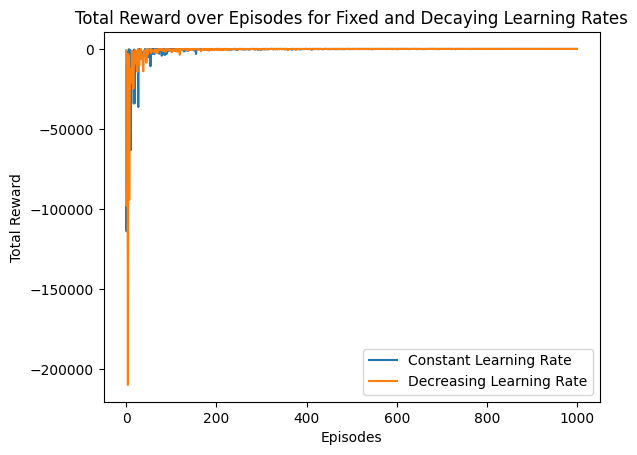

Policy with constant learning rate: [2 1 1 2 1 2 1 1 1 1 1 2 1 1 1 1 2 1 2 2 2 2 1 2 1 1 1 1 1 1 1 1 1 1 1 2 0
 0 0 0 0 0 0 0 0 0 0 0]
Policy with decreasing learning rate: [1 1 1 1 1 1 1 1 2 1 1 2 1 1 1 2 1 1 2 1 2 2 1 2 1 1 1 1 1 1 1 1 1 1 1 2 0
 0 0 0 0 0 0 0 0 0 0 0]


In [43]:

# Q-learning with constant learning rate (0.1)
agent_constant_lr = QLearning(env, learning_rate=0.1, discount=0.9, epsilon=1, epsilon_decay=0.995, min_epsilon=0.01)
regrets_constant, total_rewards_constant, frames_constant = agent_constant_lr.train(1000)

# Q-learning with decaying learning rate
agent_decreasing_lr = QLearning(env, learning_rate=0.1, discount=0.9, epsilon=1, epsilon_decay=0.995,
                                learning_rate_decay=0.99, min_lr=0.01, min_epsilon=0.01)
regrets_decreasing, total_rewards_decreasing, frames_decreasing = agent_decreasing_lr.train(1000)

# Plot the results to compare
import matplotlib.pyplot as plt

plt.plot(total_rewards_constant, label='Constant Learning Rate')
plt.plot(total_rewards_decreasing, label='Decreasing Learning Rate')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.title('Total Reward over Episodes for Fixed and Decaying Learning Rates')
plt.legend()
plt.show()

# Optional: Display the final learned policies (the best action for each state)
print("Policy with constant learning rate:", np.argmax(agent_constant_lr.q_table, axis=1))
print("Policy with decreasing learning rate:", np.argmax(agent_decreasing_lr.q_table, axis=1))

100%|██████████| 500/500 [00:00<00:00, 1086.72it/s]


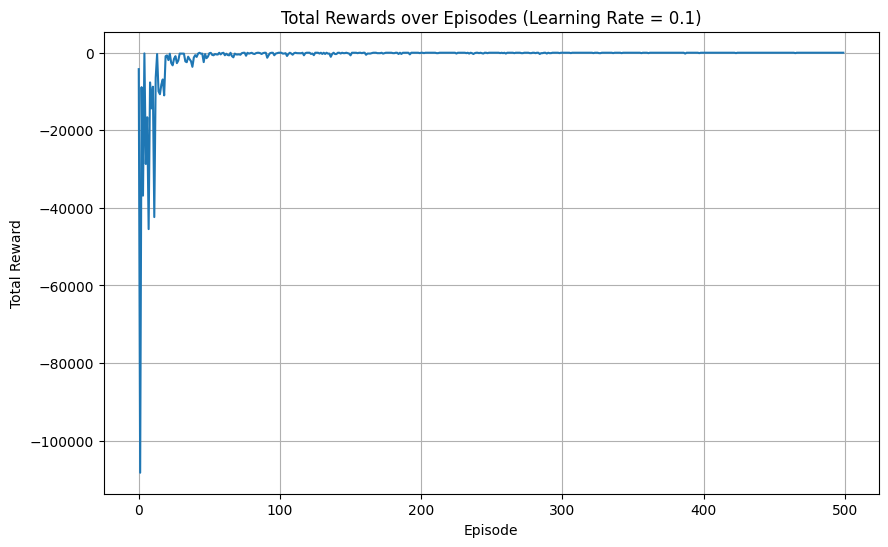

In [ ]:
agent_constant_lr = QLearning(env, learning_rate=0.1, discount=0.9, epsilon=1, epsilon_decay=0.995)
regrets_constant, total_rewards_constant, frames_constant = agent_constant_lr.train(1000)


# Plot the total rewards over episodes
plt.figure(figsize=(10, 6))
plt.plot(total_rewards)
plt.title("Total Rewards over Episodes (Learning Rate = 0.1)")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.grid()
plt.show()

100%|██████████| 500/500 [00:00<00:00, 909.71it/s]


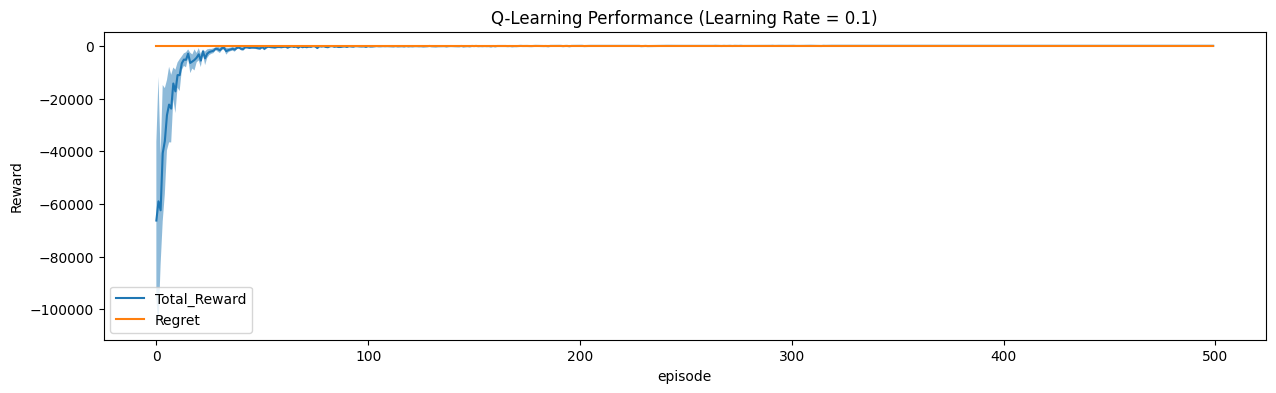

In [37]:
total_rewards_per_run, regrets_per_run = run_qlearning_experiment(env, learning_rate, discount, num_runs, num_episodes, epsilon, epsilon_decay)

plot_result(
    total_reward_per_run=total_rewards_per_run,
    regret_per_run=regrets_per_run,
    num_episodes=num_episodes,
    num_runs=num_runs,
    title="Q-Learning Performance (Learning Rate = 0.1)"
)

## Q-learning with Reduced Learning Rate (0.01)



100%|██████████| 500/500 [00:00<00:00, 1069.06it/s]


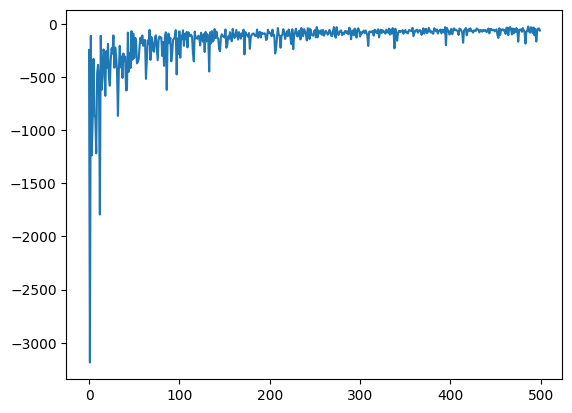

In [16]:
# Initialize QLearning agent with reduced learning rate of 0.01
agent_lr_001 = QLearning(env, learning_rate=0.01, discount=0.9, epsilon=0.1, epsilon_decay=0.99)

# Train agent for 500 episodes
regrets_lr_001, total_rewards_lr_001, _ = agent_lr_001.train(episodes=500)

# Plot or store the results (e.g., regrets, total rewards)
plt.plot(total_rewards_lr_001, label='LR = 0.01')
